# Example of the aitlas toolbox in the context of change detection

## Import the required packages

In [ ]:
from aitlas.datasets import ZY3Dataset
from aitlas.utils import image_loader
from aitlas.models import UnetChangeDetection
from aitlas.transforms import MinMaxNormTranspose, ResizeToTensor

## Visualize images and masks

Original image

Total number of patches: 1


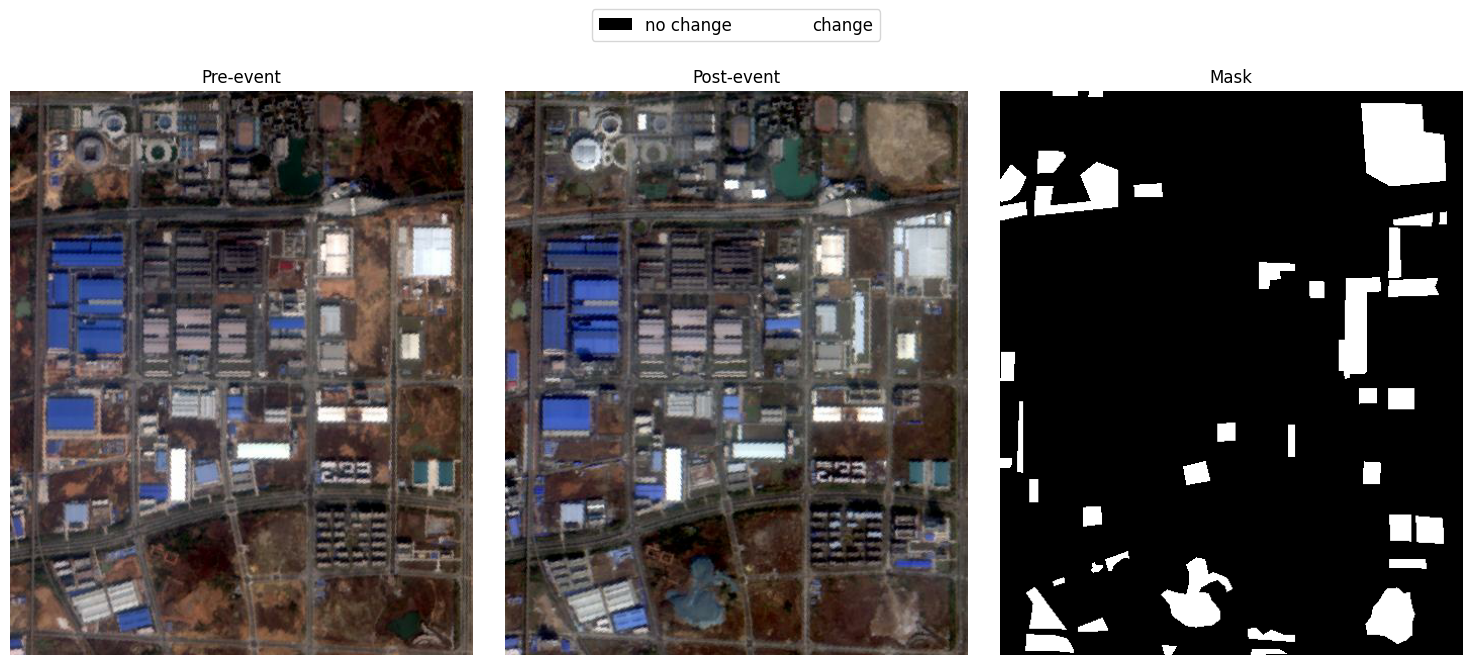

In [ ]:
dataset_config = {
    "data_dir" : "./data/zy3/",
}
dataset = ZY3Dataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")

dataset.show_image(0);

Patches of the original image

Total number of patches: 10


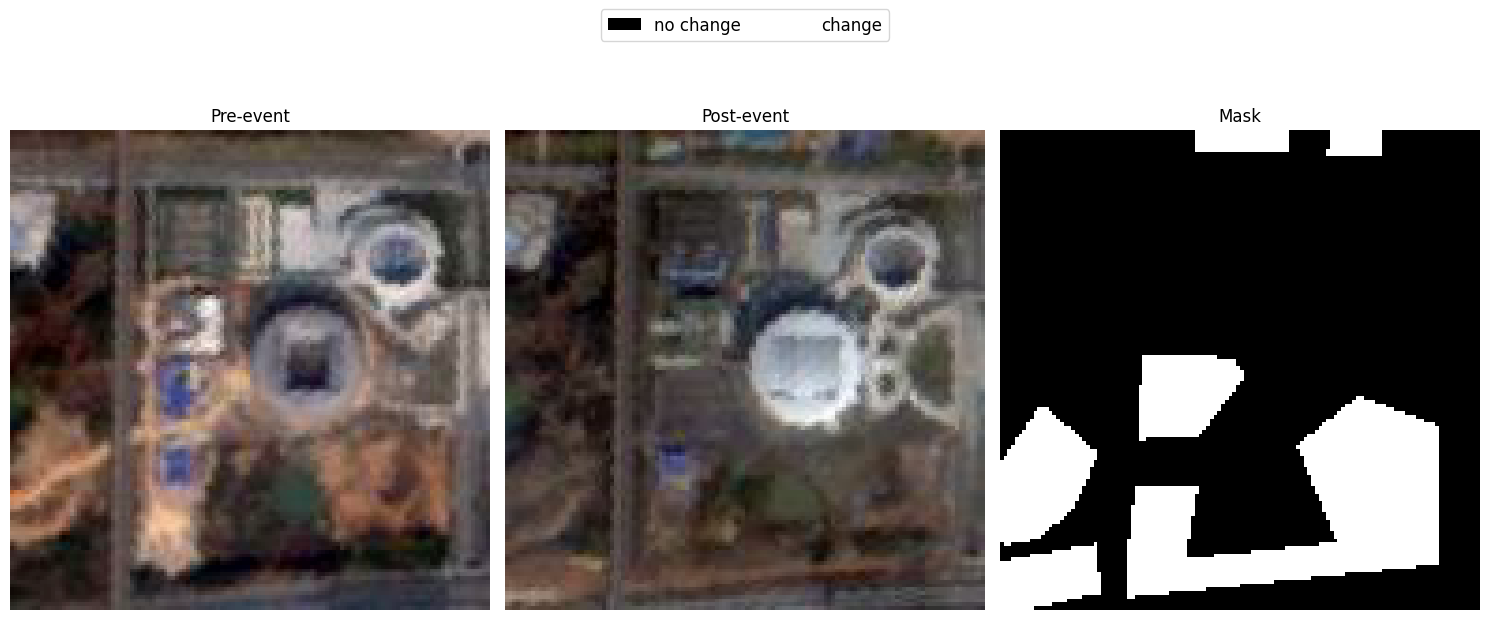

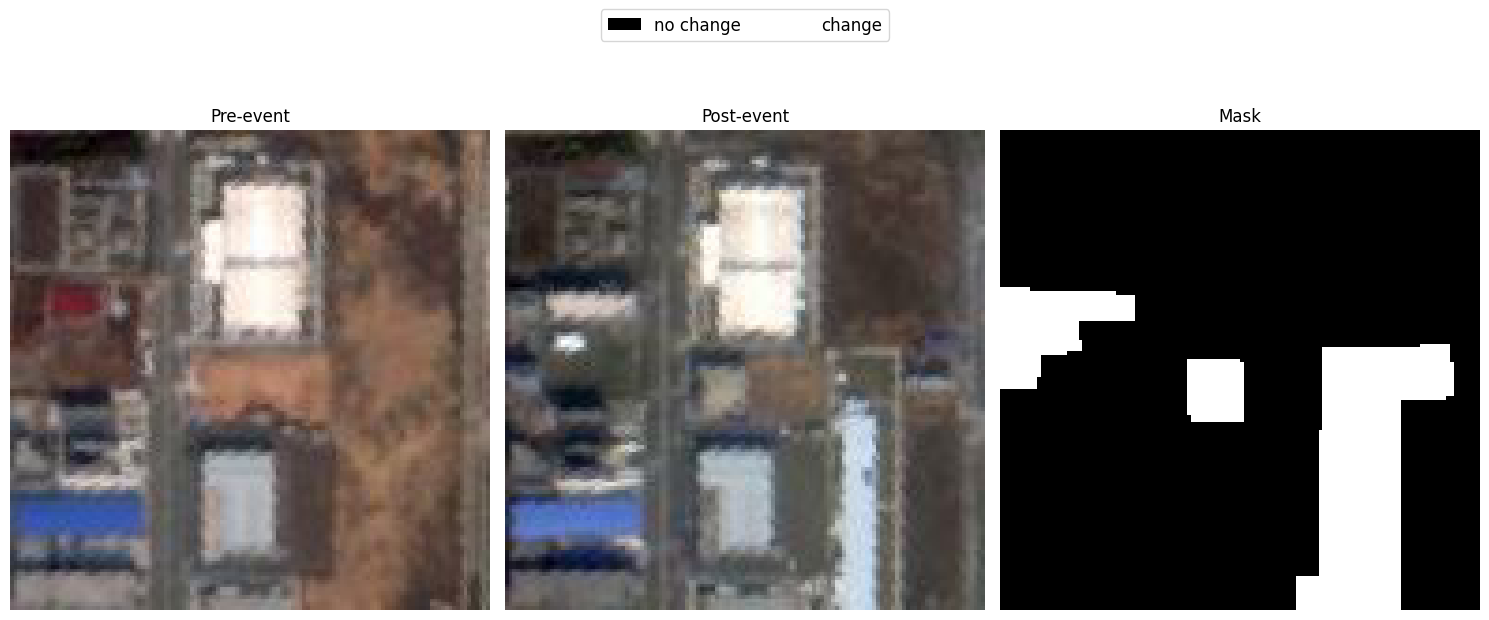

In [ ]:
dataset_config = {
    "data_dir" : "./data/zy3/",
    "mode": "train"
}
dataset = ZY3Dataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")

dataset.show_image(0)
dataset.show_image(5);

In [34]:
dataset.data_distribution_table()

,Number of pixels
no change,228827.0
change,27195.0


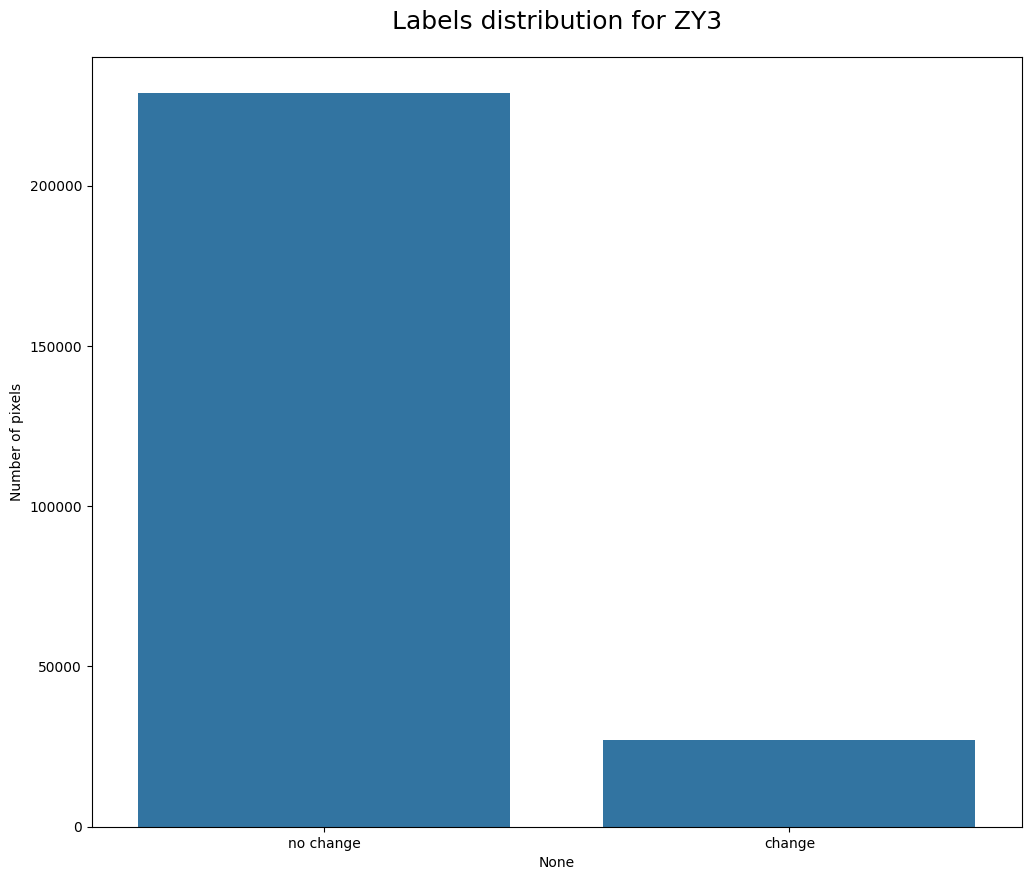

In [35]:
dataset.data_distribution_barchart();

## Load training and test data

In [ ]:
train_dataset_config = {
    "batch_size": 4,
    "shuffle": True,
    "num_workers": 4,
    "data_dir" : "./data/zy3/",
    "mode": "train",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"],
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"]
}
train_dataset = ZY3Dataset(train_dataset_config)

test_dataset_config = {
    "batch_size": 1,
    "shuffle": True,
    "num_workers": 4,
    "data_dir" : "./data/zy3/",
    "mode": "val",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"],
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"]
}
test_dataset = ZY3Dataset(test_dataset_config)
len(train_dataset), len(test_dataset)

(10, 1)

## Create the model

In [ ]:
epochs = 100
model_directory = "./data/experiments/zy3"
model_config = {
    "num_classes": 2, 
    "learning_rate": 0.0001,
    "pretrained": False, 
    "threshold": 0.5,
    "metrics": ["accuracy", "precision", "recall", "f1_score", "iou"]
}

model = UnetChangeDetection(model_config)
model.prepare()

## Start the training

In [7]:
model.train_and_evaluate_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1',
)

model_path = model_directory + "/checkpoint.pth.tar"
model.load_model(model_path)
model.running_metrics.reset()
model.evaluate(dataset=test_dataset, model_path=model_path)
test_metrics = model.running_metrics.get_scores(model.metrics)

2026-01-29 12:06:27,463 INFO Starting training.
training: 100%|██████████| 3/3 [00:01<00:00,  2.29it/s]
2026-01-29 12:06:28,816 INFO epoch: 1, loss:  0.31342
testing on train set: 100%|██████████| 3/3 [00:00<00:00,  4.01it/s]
2026-01-29 12:06:31,076 INFO Accuracy:0.07838134765625, Accuracy per Class:[0.08557739 0.0711853 ], Precision Micro:0.071185302734375, Precision Macro:0.0355926513671875, Precision Weighted:0.0051413419810939645, Precision per Class:[0.        0.0711853], Recall Micro:0.07222476808560706, Recall Macro:0.5, Recall Weighted:0.07222476808560706, Recall per Class:[0. 1.], F1_score Micro:0.07170126828188637, F1_score Macro:0.06645470447798606, F1_score Weighted:0.009599351238240192, F1_score per Class:[0.         0.13290941], IOU:0.0371836931189604, IOU mean:0.0355926513671875, IOU per Class:[0.        0.0711853]
training: 100%|██████████| 3/3 [00:00<00:00,  3.99it/s]
2026-01-29 12:06:31,832 INFO epoch: 2, loss:  0.30329
testing on train set: 100%|██████████| 3/3 [00:0

## Predictions

2026-01-29 12:09:49,944 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/zy3/checkpoint.pth.tar
2026-01-29 12:09:50,277 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/zy3/checkpoint.pth.tar at epoch 101


1


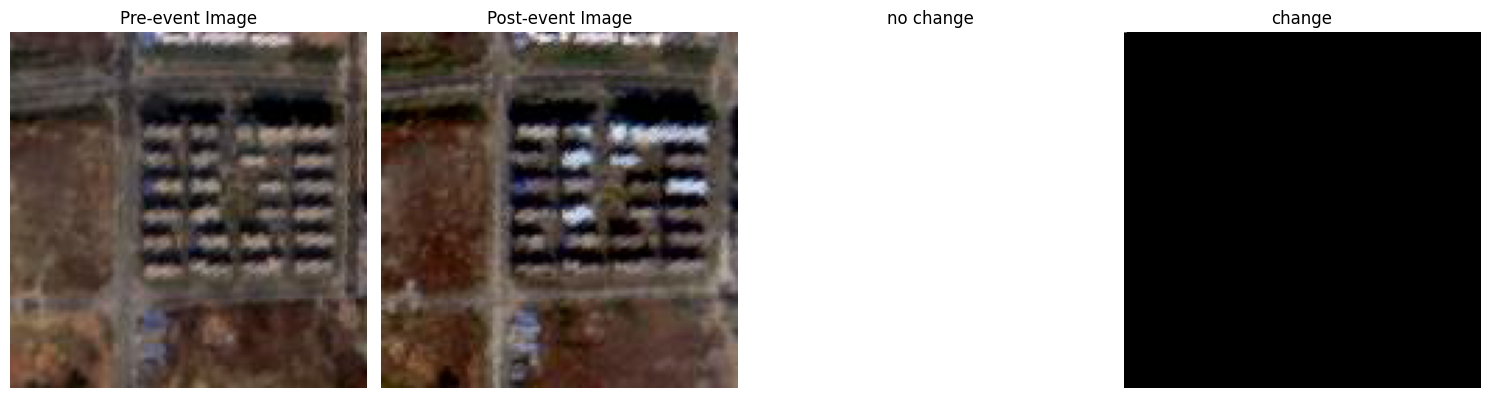

In [ ]:
model_path = "./data/experiments/zy3/checkpoint.pth.tar"
labels = ["no change","change"]
transform = ResizeToTensor()
model.load_model(model_path)

test_dataset_config = {
    "data_dir" : "./data/zy3/",
    "mode": "test"
}
test_dataset = ZY3Dataset(test_dataset_config)
print(len(test_dataset))

image1 = test_dataset[0][0][0]
image2 = test_dataset[0][0][1]
fig = model.predict_masks(image1, image2, labels, transform)